In [32]:
from utils import get_hdf5_files, get_filename, get_continuous_behaviors, get_discrete_states, get_eigenworms, get_kymograph, get_neuronal_traces

import os
import math
from matplotlib import pyplot as plt
from matplotlib import patches
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.cross_decomposition import CCA
from sklearn.metrics import r2_score
from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

import jax
import jax.numpy as jnp
import optax

from distinctipy import distinctipy

# GCAMP DATA

In [33]:
path = f'{os.getcwd()}/../data/{os.path.basename(os.getcwd())}/exported_data_/'
hdf5files = get_hdf5_files(path)
filenames = [get_filename(file) for file in hdf5files]
continuous_behaviors = [get_continuous_behaviors(file) for file in hdf5files]
discrete_states = [get_discrete_states(file) for file in hdf5files]
eigenworms = [get_eigenworms(file) for file in hdf5files]
kymographs = [get_kymograph(file) for file in hdf5files]
traces = [get_neuronal_traces(file) for file in hdf5files]

### preprocessing

In [34]:
for i in range(len(filenames)):
	mask = eigenworms[i].notna().all(axis=1)
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	discrete_states[i] = discrete_states[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	traces[i] = traces[i][mask]

	#kymographs[i] = kymographs[i][mask]
	#filenames[i] = filenames[i][mask]

### manifold

In [35]:
def get_variance_explained(X, X_rec):
	X_res = X - X_rec

	X_var = X.var().sum()
	X_res_var = X_res.var().sum()

	X_var_ratio = 1 - X_res_var / X_var

	return X_var_ratio

0.5054280287978874


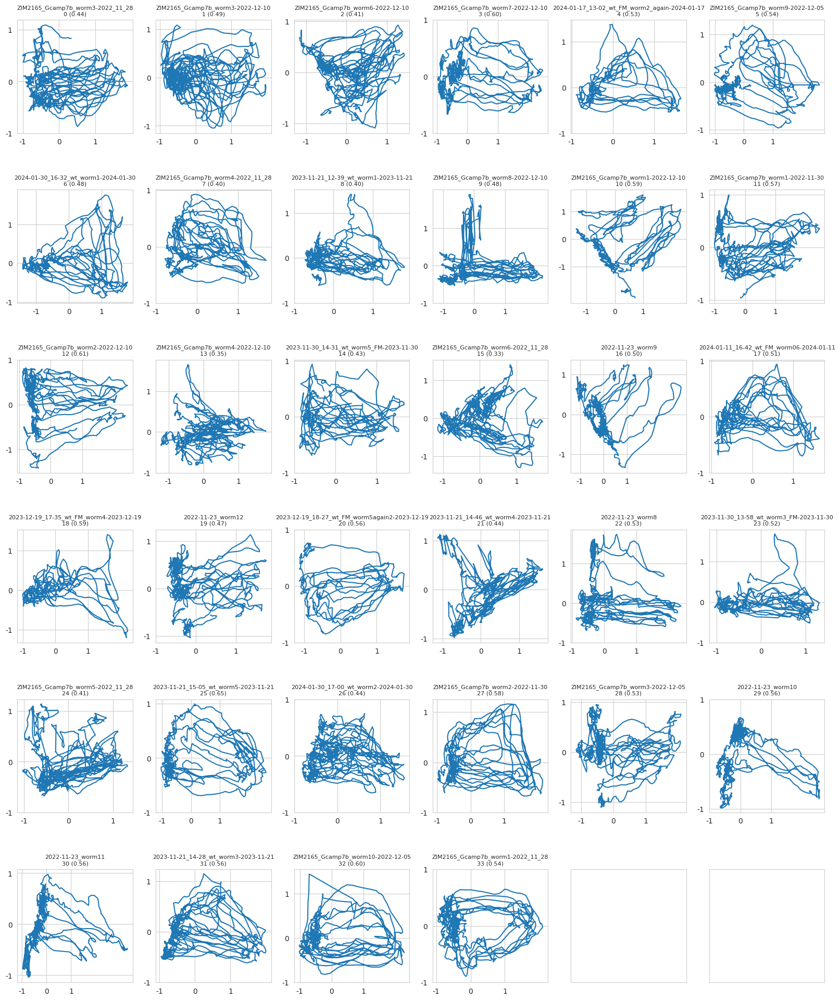

In [36]:
traces_reduced = list()
traces_reconstructed = list()
pca_loadings = list()
vars_explained_pcarec = list()  # variance explained with respect to the reconstructed PCA data
vars_explained = list()
for trace, ds in zip(traces, discrete_states):

	pca = PCA(n_components=2)
	trace_reduced_pca = pca.fit_transform(trace.values)
	trace_reconstructed_pca = pca.inverse_transform(trace_reduced_pca)
	traces_reduced.append(pd.DataFrame(data=trace_reduced_pca, columns=[f'PC{n+1}' for n in range(2)]))
	traces_reconstructed.append(pd.DataFrame(data=trace_reconstructed_pca, columns=trace.columns))

	pca_loadings.append(pca.components_)

	X_var_ratio = sum(pca.explained_variance_ratio_)
	vars_explained.append(X_var_ratio)


n_plots = 36
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(20, 24))
for i in range(n_plots):
	axes[i // dim, i % dim].set_xticklabels([])
	axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

scale = [-1, 0, 1]
for i, trace_reduced in enumerate(traces_reduced):
	axes[i // dim, i % dim].plot(trace_reduced['PC1'], trace_reduced['PC2'])
	axes[i // dim, i % dim].set_xticks(scale)
	axes[i // dim, i % dim].set_xticklabels(scale)
	axes[i // dim, i % dim].set_yticks(scale)
	axes[i // dim, i % dim].set_yticklabels(scale)
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}\n{i} ({vars_explained[i]:.2f})', fontsize=8)

plt.subplots_adjust(hspace=0.5)
print(np.mean(np.array(vars_explained)))

In [37]:
traces_residual = [pd.DataFrame(data=trace.values - trace_reconstructed.values, columns=trace.columns) for trace, trace_reconstructed in zip(traces, traces_reconstructed)]

### analytical linear regression

In [38]:
random_key = jax.random.PRNGKey(0)

models_losses_reg = list()
models_t_losses_reg = list()
models_scores_reg = list()
for i in range(len(filenames)):
	print(f'{i+1}/{len(filenames)}: {filenames[i]} ', end='')

	X, Y = eigenworms[i].values, traces_residual[i].values
	# ds_classes = np.argmax(discrete_states[i][['FWD', 'REV']].values, axis=1)

	cv = StratifiedKFold(n_splits=5)
	splits = list(cv.split(np.zeros(X.shape[0]), discrete_states[i]['REV'].values))

	loss_per_split = list()
	t_loss_per_split = list()
	score_per_split = list()
	for train, test in splits:
		X_train, X_test = X[train], X[test]
		Y_train, Y_test = Y[train], Y[test]

		model = LinearRegression()
		model.fit(X_train, Y_train)

		Y_pred = model.predict(X_test)
		loss = jnp.mean((Y_pred - Y_test) ** 2)  # loss = mean_squared_error(Y_test, Y_pred)
		t_loss = jnp.mean((model.predict(X_train) - Y_train) ** 2)  # loss = mean_squared_error(Y_test, Y_pred)
		score_per_neuron = [r2_score(trace, trace_pred) for trace, trace_pred in zip(Y_test.T, Y_pred.T)]

		loss_per_split.append(loss)
		t_loss_per_split.append(t_loss)
		score_per_split.append(np.array(score_per_neuron).mean())

	models_losses_reg.append(np.array(loss_per_split))
	models_t_losses_reg.append(np.array(t_loss_per_split))
	models_scores_reg.append(score_per_split)

1/34: ZIM2165_Gcamp7b_worm3-2022_11_28_no_image_data 2/34: ZIM2165_Gcamp7b_worm3-2022-12-10_no_image_data 3/34: ZIM2165_Gcamp7b_worm6-2022-12-10_no_image_data 4/34: ZIM2165_Gcamp7b_worm7-2022-12-10_no_image_data 5/34: 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17_no_image_data 6/34: ZIM2165_Gcamp7b_worm9-2022-12-05_no_image_data 7/34: 2024-01-30_16-32_wt_worm1-2024-01-30_no_image_data 8/34: ZIM2165_Gcamp7b_worm4-2022_11_28_no_image_data 9/34: 2023-11-21_12-39_wt_worm1-2023-11-21_no_image_data 10/34: ZIM2165_Gcamp7b_worm8-2022-12-10_no_image_data 11/34: ZIM2165_Gcamp7b_worm1-2022-12-10_no_image_data 12/34: ZIM2165_Gcamp7b_worm1-2022-11-30_no_image_data 13/34: ZIM2165_Gcamp7b_worm2-2022-12-10_no_image_data 14/34: ZIM2165_Gcamp7b_worm4-2022-12-10_no_image_data 15/34: 2023-11-30_14-31_wt_worm5_FM-2023-11-30_no_image_data 16/34: ZIM2165_Gcamp7b_worm6-2022_11_28_no_image_data 17/34: 2022-11-23_worm9_no_image_data 18/34: 2024-01-11_16-42_wt_FM_worm06-2024-01-11_no_image_data 19/34: 2023-12-19

### GLM

In [39]:
def init_params_glm(shape):
    return {
        'W': 1E-2 * jax.random.normal(random_key, shape),	# randomly initialize weights
    }

def predict_glm(W, X):
	return X @ W	# (n, p) @ (p, k) → (n, k)

def loss_fn_glm(params, X, Y):
    Y_pred = predict_glm(params['W'], X)
    return jnp.mean((Y_pred - Y) ** 2)  # MSE

@jax.jit
def update_glm(opt_state, params, X, Y):
    grads = jax.grad(loss_fn_glm)(params, X, Y)
    params_updates, opt_state = optimizer.update(grads, opt_state, params)
    params_new = optax.apply_updates(params, params_updates)
    return params_new, opt_state

In [40]:
random_key = jax.random.PRNGKey(0)
optimizer = optax.adam(1e-3)

max_epochs = 100

models_losses_glm = list()
models_t_losses_glm = list()
models_scores_glm = list()
models_epochs_glm = list()
for i in range(len(filenames)):
	print(f'{i+1}/{len(filenames)}: {filenames[i]} ', end='')

	X, Y = eigenworms[i].values, traces_residual[i].values
	# ds_classes = np.argmax(discrete_states[i][selection].values, axis=1)

	cv = StratifiedKFold(n_splits=5)
	splits = list(cv.split(np.zeros(X.shape[0]), discrete_states[i]['REV']))

	losses_per_split = list()
	t_losses_per_split = list()
	scores_per_split = list()
	epochs_per_split = list()
	for train, test in splits:
		X_train, X_test = X[train], X[test]
		Y_train, Y_test = Y[train], Y[test]

		params = init_params_glm((X.shape[1], Y.shape[1]))
		opt_state = optimizer.init(params)

		losses = [loss_fn_glm(params, X_test, Y_test).item()]
		t_losses = [loss_fn_glm(params, X_train, Y_train).item()]
		for epoch in range(max_epochs):
			params, opt_state = update_glm(opt_state, params, X_train, Y_train)
			loss = loss_fn_glm(params, X_test, Y_test).item()
			t_loss = loss_fn_glm(params, X_train, Y_train).item()
			# no early stopping
			losses.append(loss)
			t_losses.append(t_loss)
		losses_per_split.append(losses)
		t_losses_per_split.append(t_losses)

		Y_pred = predict_glm(params['W'], X_test)
		score_per_neuron = [r2_score(trace, trace_pred) for trace, trace_pred in zip(Y_test.T, Y_pred.T)]
		scores_per_split.append(score_per_neuron)

		epochs_per_split.append(max_epochs)

	# losses_per_split_avg = np.array(losses_per_split).mean(axis=0)
	models_losses_glm.append(np.array(losses_per_split))
	models_t_losses_glm.append(np.array(t_losses_per_split))

	scores_per_split_avg = np.array(scores_per_split).mean(axis=0)
	models_scores_glm.append(scores_per_split_avg)

	epochs_per_split_avg = np.array(epochs_per_split).mean()
	models_epochs_glm.append(epochs_per_split_avg)

1/34: ZIM2165_Gcamp7b_worm3-2022_11_28_no_image_data 2/34: ZIM2165_Gcamp7b_worm3-2022-12-10_no_image_data 3/34: ZIM2165_Gcamp7b_worm6-2022-12-10_no_image_data 4/34: ZIM2165_Gcamp7b_worm7-2022-12-10_no_image_data 5/34: 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17_no_image_data 6/34: ZIM2165_Gcamp7b_worm9-2022-12-05_no_image_data 7/34: 2024-01-30_16-32_wt_worm1-2024-01-30_no_image_data 8/34: ZIM2165_Gcamp7b_worm4-2022_11_28_no_image_data 9/34: 2023-11-21_12-39_wt_worm1-2023-11-21_no_image_data 10/34: ZIM2165_Gcamp7b_worm8-2022-12-10_no_image_data 11/34: ZIM2165_Gcamp7b_worm1-2022-12-10_no_image_data 12/34: ZIM2165_Gcamp7b_worm1-2022-11-30_no_image_data 13/34: ZIM2165_Gcamp7b_worm2-2022-12-10_no_image_data 14/34: ZIM2165_Gcamp7b_worm4-2022-12-10_no_image_data 15/34: 2023-11-30_14-31_wt_worm5_FM-2023-11-30_no_image_data 16/34: ZIM2165_Gcamp7b_worm6-2022_11_28_no_image_data 17/34: 2022-11-23_worm9_no_image_data 18/34: 2024-01-11_16-42_wt_FM_worm06-2024-01-11_no_image_data 19/34: 2023-12-19

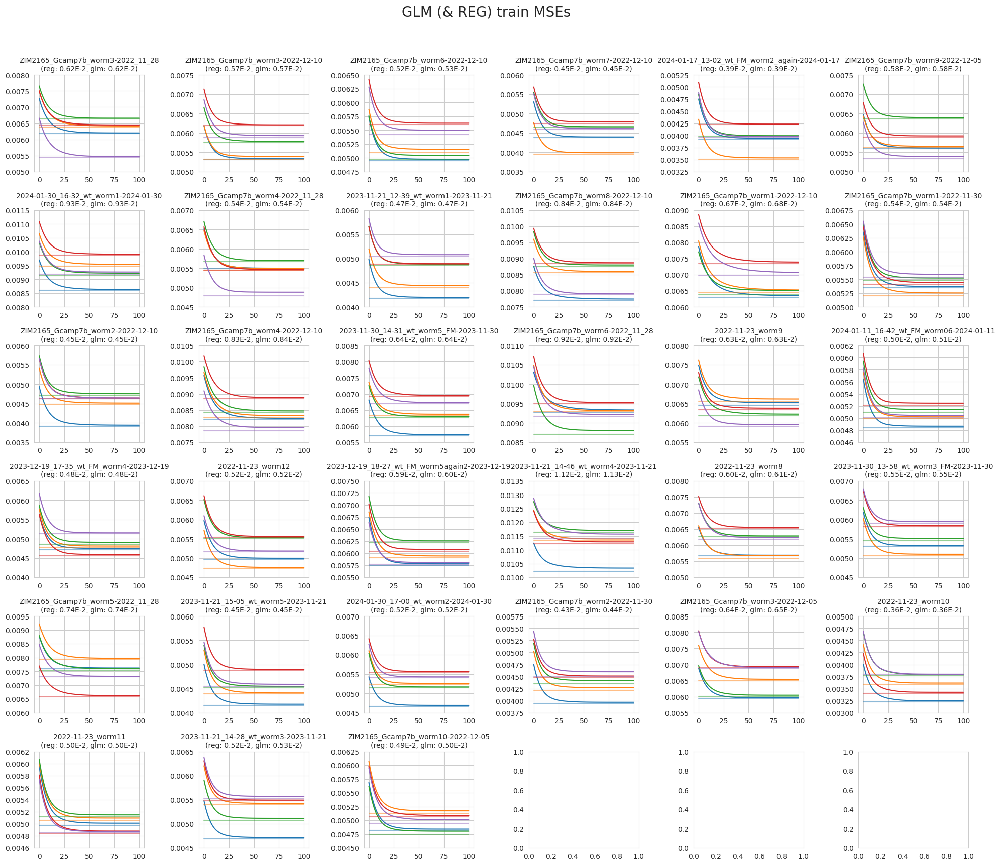

In [41]:
n_plots = 36
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(24, 20))
for i in range(n_plots):
	#axes[i // dim, i % dim].set_xticklabels([])
	#axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

for i, (losses_per_split_reg, losses_per_split_glm) in enumerate(zip(models_t_losses_reg[:33], models_t_losses_glm[:33])):
	colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
	for j, (losses_reg, losses_glm) in enumerate(zip(losses_per_split_reg, losses_per_split_glm)):
		axes[i // dim, i % dim].plot([0, 100], [losses_reg, losses_reg], color=colors[j], alpha=0.5)
		axes[i // dim, i % dim].plot(losses_glm, color=colors[j])
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}\n(reg: {np.average(losses_per_split_reg, axis=0)*100:.2f}E-2, glm: {np.average(losses_per_split_glm[:, -1], axis=0)*100:.2f}E-2)', fontsize=10)

	yticks = axes[i // dim, i % dim].get_yticks()
	axes[i // dim, i % dim].set_yticks(yticks)
	#axes[i // dim, i % dim].set_yticklabels([f'{tick * 100:.2f}E-2' for tick in yticks])

fig.subplots_adjust(hspace=0.4, wspace=0.5)
fig.suptitle('GLM (& REG) train MSEs', fontsize=20, y=0.95)
plt.savefig('./out/sep-pca-glm-reg-train-mse')
pass

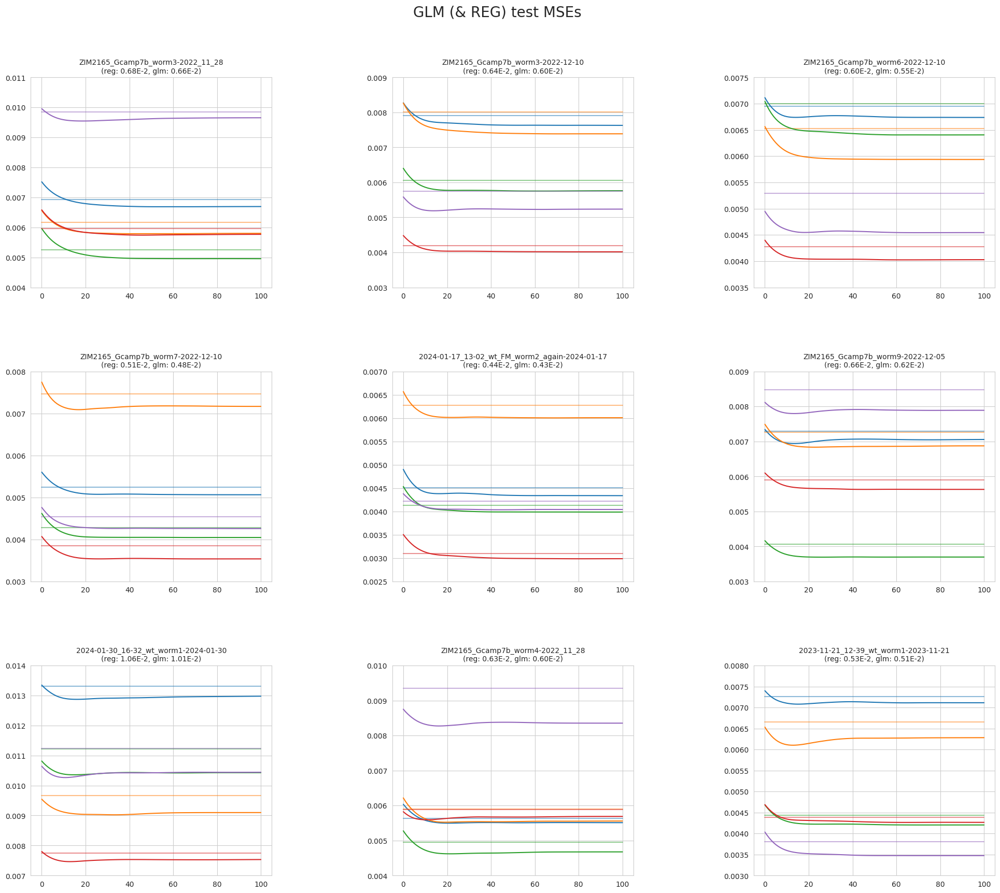

In [42]:
n_plots = 9
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(24, 20))
for i in range(n_plots):
	#axes[i // dim, i % dim].set_xticklabels([])
	#axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

for i, (losses_per_split_reg, losses_per_split_glm) in enumerate(zip(models_losses_reg[:9], models_losses_glm[:9])):
	colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
	for j, (losses_reg, losses_glm) in enumerate(zip(losses_per_split_reg, losses_per_split_glm)):
		axes[i // dim, i % dim].plot([0, 100], [losses_reg, losses_reg], color=colors[j], alpha=0.5)
		axes[i // dim, i % dim].plot(losses_glm, color=colors[j])
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}\n(reg: {np.average(losses_per_split_reg, axis=0)*100:.2f}E-2, glm: {np.average(losses_per_split_glm[:, -1], axis=0)*100:.2f}E-2)', fontsize=10)

	yticks = axes[i // dim, i % dim].get_yticks()
	axes[i // dim, i % dim].set_yticks(yticks)
	#axes[i // dim, i % dim].set_yticklabels([f'{tick * 100:.2f}E-2' for tick in yticks])

fig.subplots_adjust(hspace=0.4, wspace=0.5)
fig.suptitle('GLM (& REG) test MSEs', fontsize=20, y=0.95)
plt.savefig('./out/sep-pca-glm-reg-test-mse')
pass

### HGM

In [43]:
def init_params_hgm(shape_X, shape_X_man):
    return {
        'W1': 1E-2 * jax.random.normal(random_key, shape_X),	# randomly initialize weights
        'W2': 1E-2 * jax.random.normal(random_key, shape_X_man)
    }

def predict_hgm(W_1, W_2, X, X_man):
	return X @ W_1 * jax.nn.sigmoid(X_man @ W_2)	# (n, p) @ (p, k) → (n, k)

def loss_fn_hgm(params, X, X_man, Y):
    Y_pred = predict_hgm(params['W1'], params['W2'], X, X_man)
    return jnp.mean((Y_pred - Y) ** 2)  # MSE

@jax.jit
def update_hgm(opt_state, params, X, X_man, Y):
    grads = jax.grad(loss_fn_hgm)(params, X, X_man, Y)
    params_updates, opt_state = optimizer.update(grads, opt_state, params)
    params_new = optax.apply_updates(params, params_updates)
    return params_new, opt_state

In [44]:
random_key = jax.random.PRNGKey(0)
optimizer = optax.adam(1e-3)

max_epochs = 100
min_epochs = 10
max_patience = 20

models_params_hgm = list()
models_losses_hgm = list()
models_t_losses_hgm = list()
models_scores_hgm = list()
models_epochs_hgm = list()
for i in range(len(filenames)):
	print(f'{i+1}/{len(filenames)}: {filenames[i]}  ', end='')

	X, X_man, Y = eigenworms[i].values, traces_reduced[i].values, traces_residual[i].values
	# ds_classes = np.argmax(discrete_states[i][selection].values, axis=1)

	cv = StratifiedKFold(n_splits=5)
	splits = list(cv.split(np.zeros(X.shape[0]), discrete_states[i]['REV'].values))

	losses_per_split = list()
	t_losses_per_split = list()
	scores_per_split = list()
	epochs_per_split = list()
	for train, test in splits:
		X_train, X_test = X[train], X[test]
		X_man_train, X_man_test = X_man[train], X_man[test]
		Y_train, Y_test = Y[train], Y[test]

		params = init_params_hgm((X.shape[1], Y.shape[1]), (X_man.shape[1], Y.shape[1]))
		opt_state = optimizer.init(params)

		best_params = params
		best_loss = 1.1

		patience = 0
		losses = [loss_fn_hgm(params, X_test, X_man_test, Y_test).item()]
		t_losses = [loss_fn_hgm(params, X_train, X_man_train, Y_train).item()]
		for epoch in range(max_epochs):
			params, opt_state = update_hgm(opt_state, params, X_train, X_man_train, Y_train)
			loss = loss_fn_hgm(params, X_test, X_man_test, Y_test).item()
			t_loss = loss_fn_hgm(params, X_train, X_man_train, Y_train).item()
			# early stopping =============
			if epoch > min_epochs:
				if loss < best_loss:
					losses.append(loss)
					t_losses.append(t_loss)
					best_loss = loss
					best_params = params
					patience = 0
				else:
					patience += 1
					if patience > max_patience:
						losses_padding = [best_loss for _ in range(max_epochs - len(losses) + 1)]
						t_losses_padding = [t_losses[-1] for _ in range(max_epochs - len(t_losses) + 1)]
						losses = losses + losses_padding
						t_losses = t_losses + t_losses_padding
						epochs_per_split.append(epoch + 1)
						break
					losses.append(loss)
					t_losses.append(t_loss)
			# ============================
			else:
				losses.append(loss)
				t_losses.append(t_loss)
		losses_per_split.append(losses)
		t_losses_per_split.append(t_losses)

		Y_pred = predict_hgm(best_params['W1'], best_params['W2'], X_test, X_man_test)
		score_per_neuron = [r2_score(trace, trace_pred) for trace, trace_pred in zip(Y_test.T, Y_pred.T)]
		scores_per_split.append(score_per_neuron)

		if len(epochs_per_split) == 0:
			epochs_per_split.append(max_epochs)

	models_t_losses_hgm.append(np.array(t_losses_per_split))
	models_losses_hgm.append(np.array(losses_per_split))

	scores_per_split_avg = np.array(scores_per_split).mean(axis=0)
	models_scores_hgm.append(scores_per_split_avg)

	epochs_per_split_avg = np.array(epochs_per_split).mean()
	models_epochs_hgm.append(epochs_per_split_avg)

1/34: ZIM2165_Gcamp7b_worm3-2022_11_28_no_image_data  2/34: ZIM2165_Gcamp7b_worm3-2022-12-10_no_image_data  3/34: ZIM2165_Gcamp7b_worm6-2022-12-10_no_image_data  4/34: ZIM2165_Gcamp7b_worm7-2022-12-10_no_image_data  5/34: 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17_no_image_data  6/34: ZIM2165_Gcamp7b_worm9-2022-12-05_no_image_data  7/34: 2024-01-30_16-32_wt_worm1-2024-01-30_no_image_data  8/34: ZIM2165_Gcamp7b_worm4-2022_11_28_no_image_data  9/34: 2023-11-21_12-39_wt_worm1-2023-11-21_no_image_data  10/34: ZIM2165_Gcamp7b_worm8-2022-12-10_no_image_data  11/34: ZIM2165_Gcamp7b_worm1-2022-12-10_no_image_data  12/34: ZIM2165_Gcamp7b_worm1-2022-11-30_no_image_data  13/34: ZIM2165_Gcamp7b_worm2-2022-12-10_no_image_data  14/34: ZIM2165_Gcamp7b_worm4-2022-12-10_no_image_data  15/34: 2023-11-30_14-31_wt_worm5_FM-2023-11-30_no_image_data  16/34: ZIM2165_Gcamp7b_worm6-2022_11_28_no_image_data  17/34: 2022-11-23_worm9_no_image_data  18/34: 2024-01-11_16-42_wt_FM_worm06-2024-01-11_no_image_data 

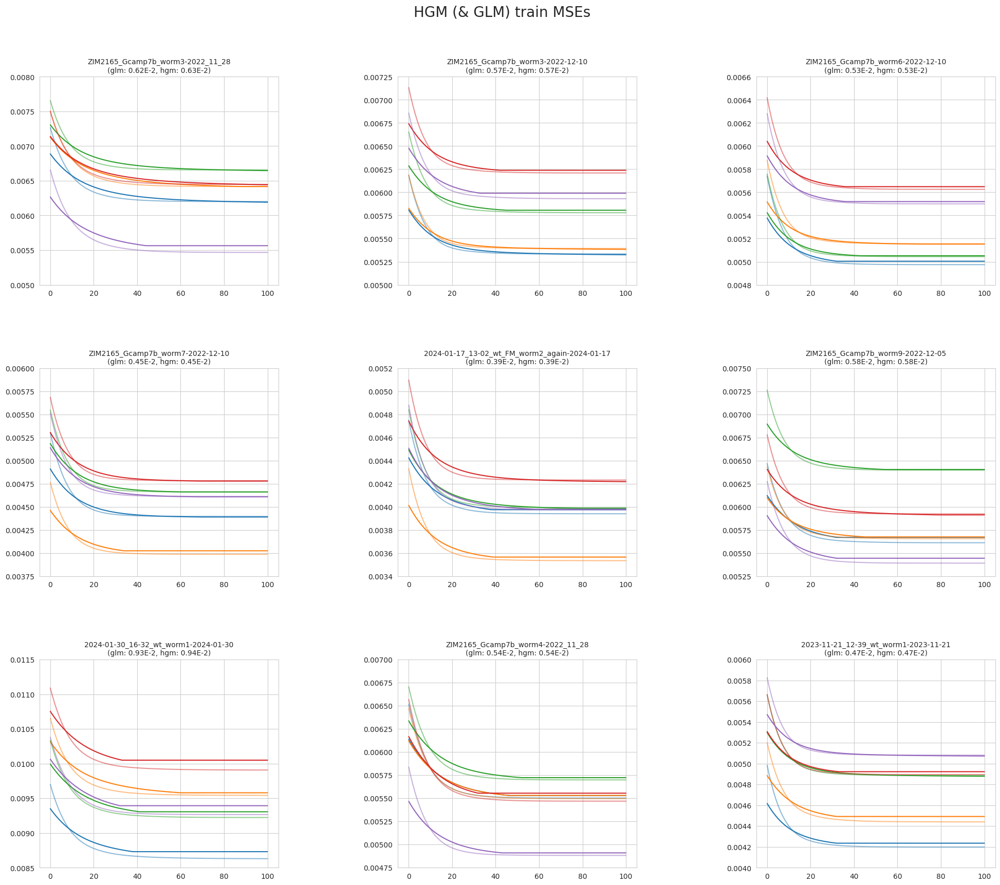

In [45]:
n_plots = 9
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(24, 20))
for i in range(n_plots):
	#axes[i // dim, i % dim].set_xticklabels([])
	#axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

for i, (losses_per_split_glm, losses_per_split_hgm) in enumerate(zip(models_t_losses_glm[:9], models_t_losses_hgm[:9])):
	colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
	for j, (losses_glm, losses_hgm) in enumerate(zip(losses_per_split_glm, losses_per_split_hgm)):
		axes[i // dim, i % dim].plot(losses_glm, color=colors[j], alpha=0.5)
		axes[i // dim, i % dim].plot(losses_hgm, color=colors[j])
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}\n(glm: {np.average(losses_per_split_glm[:, -1], axis=0)*100:.2f}E-2, hgm: {np.average(losses_per_split_hgm[:, -1], axis=0)*100:.2f}E-2)', fontsize=10)

	yticks = axes[i // dim, i % dim].get_yticks()
	axes[i // dim, i % dim].set_yticks(yticks)
	#axes[i // dim, i % dim].set_yticklabels([f'{tick * 100:.2f}E-2' for tick in yticks])

fig.subplots_adjust(hspace=0.4, wspace=0.5)
fig.suptitle('HGM (& GLM) train MSEs', fontsize=20, y=0.95)
plt.savefig('./out/sep-pca-hgm-glm-train-mse')
pass

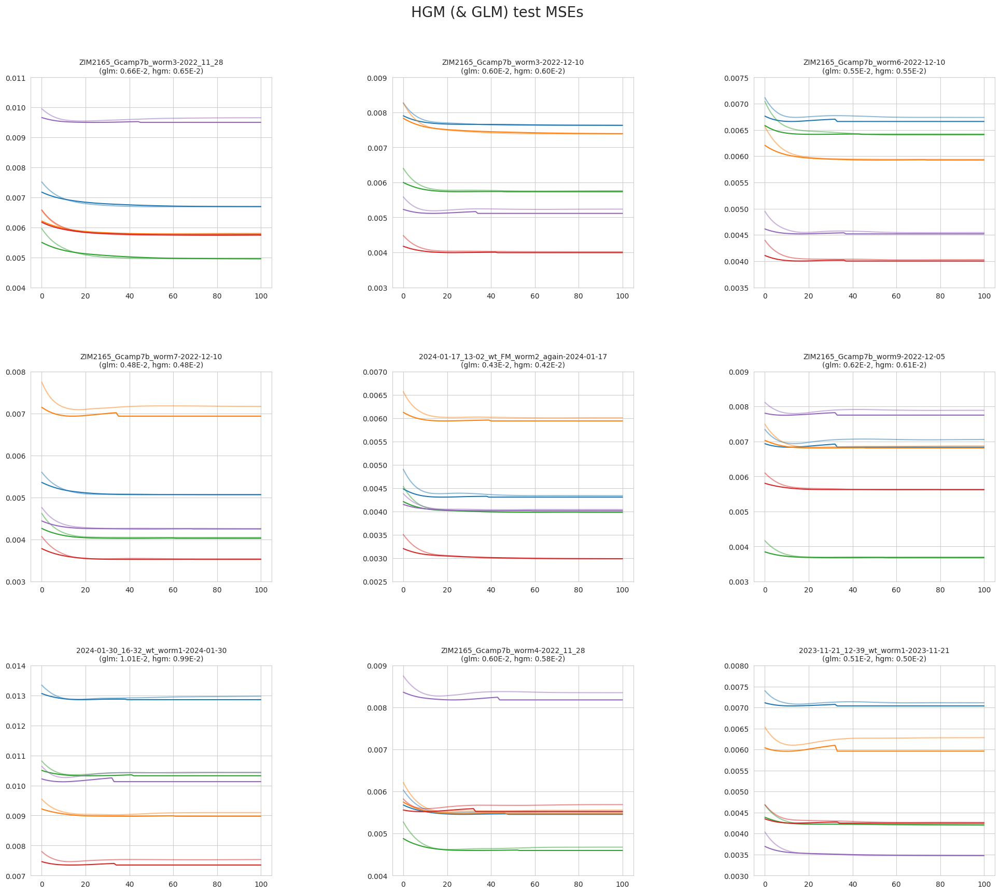

In [46]:
n_plots = 9
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(24, 20))
for i in range(n_plots):
	#axes[i // dim, i % dim].set_xticklabels([])
	#axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

for i, (losses_per_split_glm, losses_per_split_hgm) in enumerate(zip(models_losses_glm[:9], models_losses_hgm[:9])):
	colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
	for j, (losses_glm, losses_hgm) in enumerate(zip(losses_per_split_glm, losses_per_split_hgm)):
		axes[i // dim, i % dim].plot(losses_glm, color=colors[j], alpha=0.5)
		axes[i // dim, i % dim].plot(losses_hgm, color=colors[j])
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}\n(glm: {np.average(losses_per_split_glm[:, -1], axis=0)*100:.2f}E-2, hgm: {np.average(losses_per_split_hgm[:, -1], axis=0)*100:.2f}E-2)', fontsize=10)

	yticks = axes[i // dim, i % dim].get_yticks()
	axes[i // dim, i % dim].set_yticks(yticks)
	#axes[i // dim, i % dim].set_yticklabels([f'{tick * 100:.2f}E-2' for tick in yticks])

fig.subplots_adjust(hspace=0.4, wspace=0.5)
fig.suptitle('HGM (& GLM) test MSEs', fontsize=20, y=0.95)
plt.savefig('./out/sep-pca-hgm-glm-test-mse')
pass

# GFP DATA

In [47]:
path = f'{os.getcwd()}/../data/{os.path.basename(os.getcwd())}/exported_data_gfp/'
gfp_hdf5files = get_hdf5_files(path)
gfp_filenames = [get_filename(file) for file in gfp_hdf5files]
gfp_continuous_behaviors = [get_continuous_behaviors(file) for file in gfp_hdf5files]
gfp_discrete_states = [get_discrete_states(file) for file in gfp_hdf5files]
gfp_eigenworms = [get_eigenworms(file) for file in gfp_hdf5files]
gfp_kymographs = [get_kymograph(file) for file in gfp_hdf5files]
gfp_traces = [get_neuronal_traces(file) for file in gfp_hdf5files]

for i in range(len(gfp_filenames)):
	mask = gfp_eigenworms[i].notna().all(axis=1)
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	gfp_discrete_states[i] = gfp_discrete_states[i][mask]
	gfp_eigenworms[i] = gfp_eigenworms[i][mask]
	gfp_traces[i] = gfp_traces[i][mask]

	#gfp_kymographs[i] = gfp_kymographs[i][mask]
	#gfp_filenames[i] = gfp_filenames[i][mask]

### manifold

0.3972001497929929


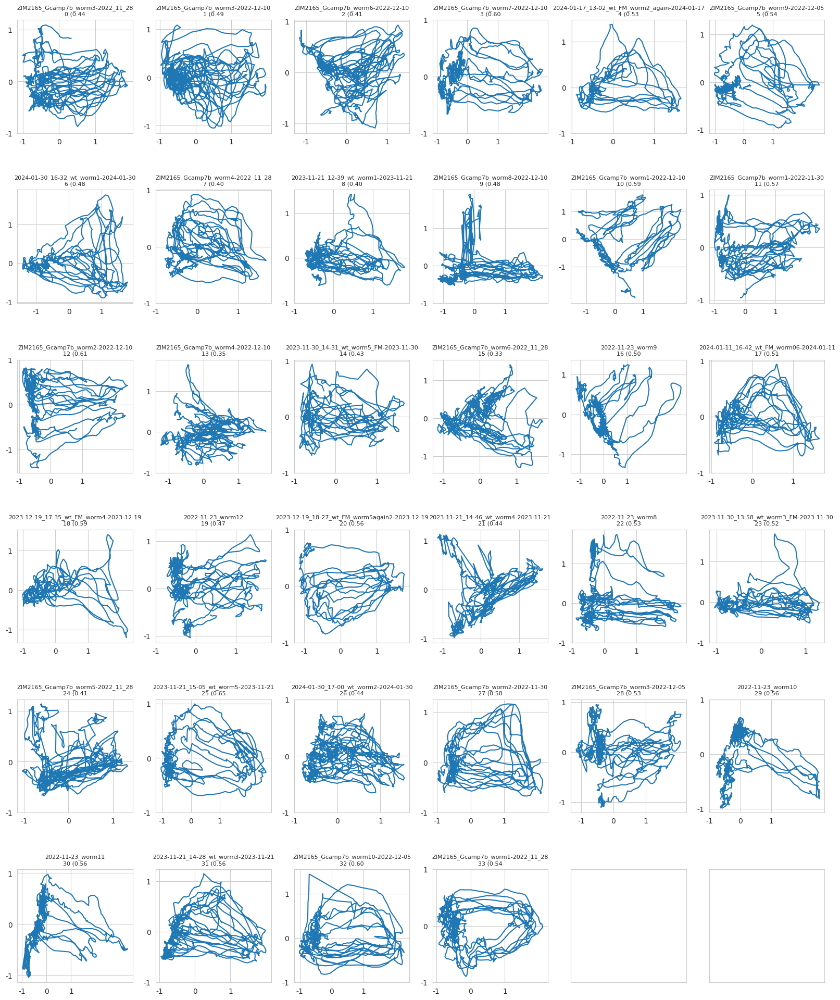

In [48]:
gfp_traces_reduced = list()
gfp_traces_reconstructed = list()
gfp_cca_loadings = list()
gfp_vars_explained_pcarec = list()  # variance explained with respect to the reconstructed PCA data
gfp_vars_explained = list()
for trace, ds in zip(gfp_traces, gfp_discrete_states):

	pca = PCA(n_components=2)
	trace_reduced_pca = pca.fit_transform(trace.values)
	trace_reconstructed_pca = pca.inverse_transform(trace_reduced_pca)
	gfp_traces_reduced.append(pd.DataFrame(data=trace_reduced_pca, columns=[f'PC{n+1}' for n in range(2)]))
	gfp_traces_reconstructed.append(pd.DataFrame(data=trace_reconstructed_pca, columns=trace.columns))

	gfp_pca_loadings.append(pca.components_)

	X_var_ratio = sum(pca.explained_variance_ratio_)
	gfp_vars_explained.append(X_var_ratio)


n_plots = 36
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(20, 24))
for i in range(n_plots):
	axes[i // dim, i % dim].set_xticklabels([])
	axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

scale = [-1, 0, 1]
for i, trace_reduced in enumerate(traces_reduced):
	axes[i // dim, i % dim].plot(trace_reduced['PC1'], trace_reduced['PC2'])
	axes[i // dim, i % dim].set_xticks(scale)
	axes[i // dim, i % dim].set_xticklabels(scale)
	axes[i // dim, i % dim].set_yticks(scale)
	axes[i // dim, i % dim].set_yticklabels(scale)
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}\n{i} ({vars_explained[i]:.2f}', fontsize=8)

plt.subplots_adjust(hspace=0.5)
print(np.mean(np.array(gfp_vars_explained)))

In [49]:
gfp_traces_residual = [pd.DataFrame(data=trace.values - trace_reconstructed.values, columns=trace.columns) for trace, trace_reconstructed in zip(gfp_traces, gfp_traces_reconstructed)]

### analytical linear regression

In [50]:
random_key = jax.random.PRNGKey(0)

gfp_models_losses_reg = list()
gfp_models_t_losses_reg = list()
gfp_models_scores_reg = list()
for i in range(len(gfp_filenames)):
	print(f'{i+1}/{len(gfp_filenames)}: {gfp_filenames[i]} ', end='')

	X, Y = gfp_eigenworms[i].values, gfp_traces_residual[i].values
	# ds_classes = np.argmax(gfp_discrete_states[i][['FWD', 'REV']].values, axis=1)

	cv = StratifiedKFold(n_splits=5)
	splits = list(cv.split(np.zeros(X.shape[0]), gfp_discrete_states[i]['REV'].values))

	loss_per_split = list()
	t_loss_per_split = list()
	score_per_split = list()
	for train, test in splits:
		X_train, X_test = X[train], X[test]
		Y_train, Y_test = Y[train], Y[test]

		model = LinearRegression()
		model.fit(X_train, Y_train)

		Y_pred = model.predict(X_test)
		loss = jnp.mean((Y_pred - Y_test) ** 2)  # loss = mean_squared_error(Y_test, Y_pred)
		t_loss = jnp.mean((model.predict(X_train) - Y_train) ** 2)  # loss = mean_squared_error(Y_test, Y_pred)
		score_per_neuron = [r2_score(trace, trace_pred) for trace, trace_pred in zip(Y_test.T, Y_pred.T)]

		loss_per_split.append(loss)
		t_loss_per_split.append(t_loss)
		score_per_split.append(np.array(score_per_neuron).mean())

	gfp_models_losses_reg.append(np.array(loss_per_split))
	gfp_models_t_losses_reg.append(np.array(t_loss_per_split))
	gfp_models_scores_reg.append(score_per_split)

1/8: ZIM2319_GFP_worm3-2022-12-10_no_image_data 2/8: ZIM2319_GFP_worm1-2022-12-10_no_image_data 3/8: ZIM2319_GFP_worm2-2022-12-10_no_image_data 4/8: ZIM2319_GFP_worm6-2022-12-10_no_image_data 5/8: ZIM2319_GFP_worm8-2022-12-10_no_image_data 6/8: ZIM2319_GFP_worm4-2022-12-10_no_image_data 7/8: ZIM2319_GFP_worm7-2022-12-10_no_image_data 8/8: ZIM2319_GFP_worm5-2022-12-10_no_image_data 

### GLM

In [51]:
random_key = jax.random.PRNGKey(0)
optimizer = optax.adam(1e-3)

max_epochs = 100

gfp_models_losses_glm = list()
gfp_models_t_losses_glm = list()
gfp_models_scores_glm = list()
gfp_models_epochs_glm = list()
for i in range(len(gfp_filenames)):
	print(f'{i+1}/{len(gfp_filenames)}: {gfp_filenames[i]} ', end='')

	X, Y = gfp_eigenworms[i].values, gfp_traces_residual[i].values
	# ds_classes = np.argmax(gfp_discrete_states[i][selection].values, axis=1)

	cv = StratifiedKFold(n_splits=5)
	splits = list(cv.split(np.zeros(X.shape[0]), gfp_discrete_states[i]['REV']))

	losses_per_split = list()
	t_losses_per_split = list()
	scores_per_split = list()
	epochs_per_split = list()
	for train, test in splits:
		X_train, X_test = X[train], X[test]
		Y_train, Y_test = Y[train], Y[test]

		params = init_params_glm((X.shape[1], Y.shape[1]))
		opt_state = optimizer.init(params)

		losses = [loss_fn_glm(params, X_test, Y_test).item()]
		t_losses = [loss_fn_glm(params, X_train, Y_train).item()]
		for epoch in range(max_epochs):
			params, opt_state = update_glm(opt_state, params, X_train, Y_train)
			loss = loss_fn_glm(params, X_test, Y_test).item()
			t_loss = loss_fn_glm(params, X_train, Y_train).item()
			# no early stopping
			losses.append(loss)
			t_losses.append(t_loss)
		losses_per_split.append(losses)
		t_losses_per_split.append(t_losses)

		Y_pred = predict_glm(params['W'], X_test)
		score_per_neuron = [r2_score(trace, trace_pred) for trace, trace_pred in zip(Y_test.T, Y_pred.T)]
		scores_per_split.append(score_per_neuron)

		epochs_per_split.append(max_epochs)

	# losses_per_split_avg = np.array(losses_per_split).mean(axis=0)
	gfp_models_losses_glm.append(np.array(losses_per_split))
	gfp_models_t_losses_glm.append(np.array(t_losses_per_split))

	scores_per_split_avg = np.array(scores_per_split).mean(axis=0)
	gfp_models_scores_glm.append(scores_per_split_avg)

	epochs_per_split_avg = np.array(epochs_per_split).mean()
	gfp_models_epochs_glm.append(epochs_per_split_avg)

1/8: ZIM2319_GFP_worm3-2022-12-10_no_image_data 2/8: ZIM2319_GFP_worm1-2022-12-10_no_image_data 3/8: ZIM2319_GFP_worm2-2022-12-10_no_image_data 4/8: ZIM2319_GFP_worm6-2022-12-10_no_image_data 5/8: ZIM2319_GFP_worm8-2022-12-10_no_image_data 6/8: ZIM2319_GFP_worm4-2022-12-10_no_image_data 7/8: ZIM2319_GFP_worm7-2022-12-10_no_image_data 8/8: ZIM2319_GFP_worm5-2022-12-10_no_image_data 

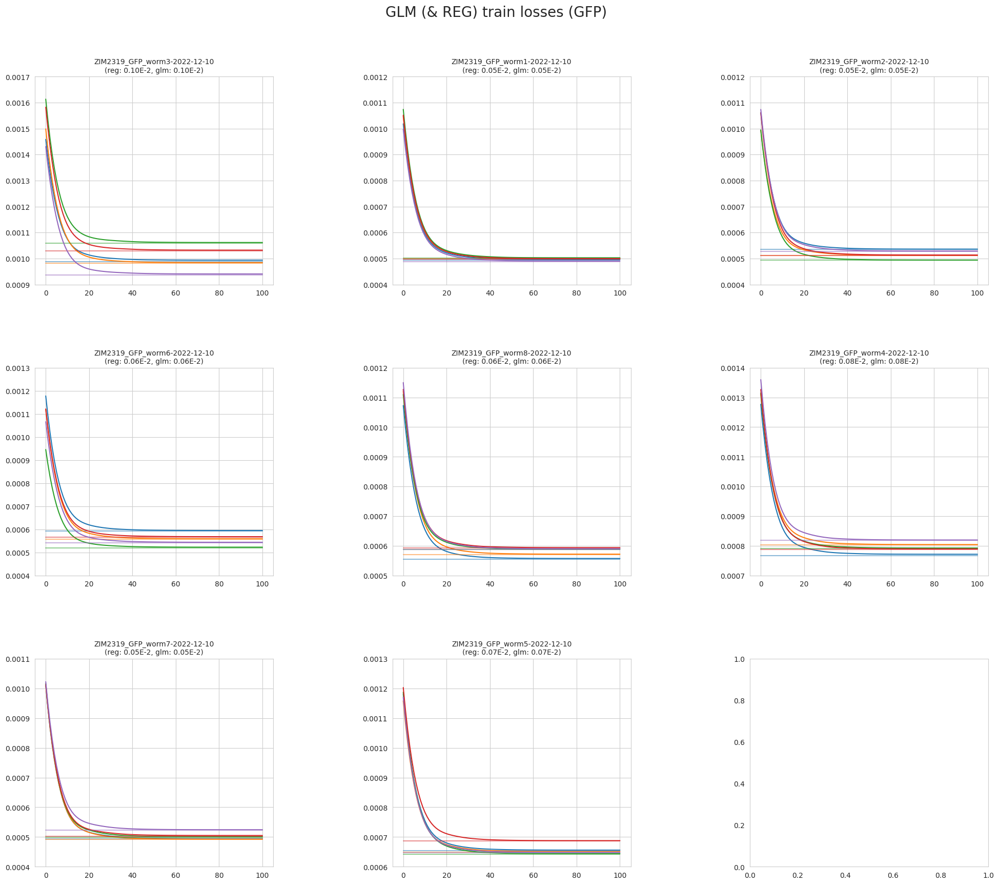

In [52]:
n_plots = 9
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(24, 20))
for i in range(n_plots):
	#axes[i // dim, i % dim].set_xticklabels([])
	#axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

for i, (losses_per_split_reg, losses_per_split_glm) in enumerate(zip(gfp_models_t_losses_reg[:9], gfp_models_t_losses_glm[:9])):
	colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
	for j, (losses_reg, losses_glm) in enumerate(zip(losses_per_split_reg, losses_per_split_glm)):
		axes[i // dim, i % dim].plot([0, 100], [losses_reg, losses_reg], color=colors[j], alpha=0.5)
		axes[i // dim, i % dim].plot(losses_glm, color=colors[j])
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{gfp_filenames[i][:-14]}\n(reg: {np.average(losses_per_split_reg, axis=0)*100:.2f}E-2, glm: {np.average(losses_per_split_glm[:, -1], axis=0)*100:.2f}E-2)', fontsize=10)

	yticks = axes[i // dim, i % dim].get_yticks()
	axes[i // dim, i % dim].set_yticks(yticks)
	#axes[i // dim, i % dim].set_yticklabels([f'{tick * 100:.2f}E-2' for tick in yticks])

fig.subplots_adjust(hspace=0.4, wspace=0.5)
fig.suptitle('GLM (& REG) train losses (GFP)', fontsize=20, y=0.95)
plt.savefig('./out/sep-pca-glm-reg-train-mse-gfp')
pass

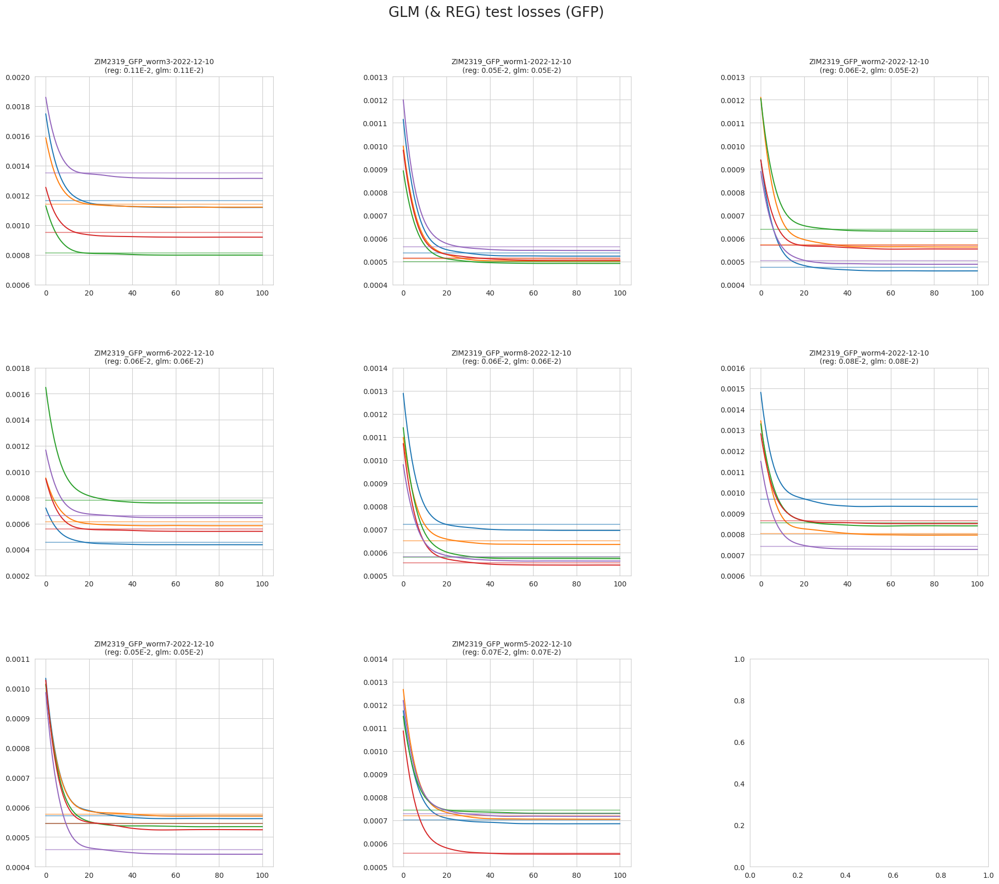

In [53]:
n_plots = 9
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(24, 20))
for i in range(n_plots):
	#axes[i // dim, i % dim].set_xticklabels([])
	#axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

for i, (losses_per_split_reg, losses_per_split_glm) in enumerate(zip(gfp_models_losses_reg[:9], gfp_models_losses_glm[:9])):
	colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
	for j, (losses_reg, losses_glm) in enumerate(zip(losses_per_split_reg, losses_per_split_glm)):
		axes[i // dim, i % dim].plot([0, 100], [losses_reg, losses_reg], color=colors[j], alpha=0.5)
		axes[i // dim, i % dim].plot(losses_glm, color=colors[j])
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{gfp_filenames[i][:-14]}\n(reg: {np.average(losses_per_split_reg, axis=0)*100:.2f}E-2, glm: {np.average(losses_per_split_glm[:, -1], axis=0)*100:.2f}E-2)', fontsize=10)

	yticks = axes[i // dim, i % dim].get_yticks()
	axes[i // dim, i % dim].set_yticks(yticks)
	#axes[i // dim, i % dim].set_yticklabels([f'{tick * 100:.2f}E-2' for tick in yticks])

fig.subplots_adjust(hspace=0.4, wspace=0.5)
fig.suptitle('GLM (& REG) test losses (GFP)', fontsize=20, y=0.95)
plt.savefig('./out/sep-pca-glm-reg-test-mse-gfp')
pass

### HGM

In [54]:
random_key = jax.random.PRNGKey(0)
optimizer = optax.adam(1e-3)

max_epochs = 100
min_epochs = 10
max_patience = 20

gfp_models_params_hgm = list()
gfp_models_losses_hgm = list()
gfp_models_t_losses_hgm = list()
gfp_models_scores_hgm = list()
gfp_models_epochs_hgm = list()
for i in range(len(gfp_filenames)):
	print(f'{i+1}/{len(gfp_filenames)}: {gfp_filenames[i]}  ', end='')

	X, X_man, Y = gfp_eigenworms[i].values, gfp_traces_reduced[i].values, gfp_traces_residual[i].values
	# ds_classes = np.argmax(gfp_discrete_states[i][selection].values, axis=1)

	cv = StratifiedKFold(n_splits=5)
	splits = list(cv.split(np.zeros(X.shape[0]), gfp_discrete_states[i]['REV'].values))

	losses_per_split = list()
	t_losses_per_split = list()
	scores_per_split = list()
	epochs_per_split = list()
	for train, test in splits:
		X_train, X_test = X[train], X[test]
		X_man_train, X_man_test = X_man[train], X_man[test]
		Y_train, Y_test = Y[train], Y[test]

		params = init_params_hgm((X.shape[1], Y.shape[1]), (X_man.shape[1], Y.shape[1]))
		opt_state = optimizer.init(params)

		best_params = params
		best_loss = 1.1

		patience = 0
		losses = [loss_fn_hgm(params, X_test, X_man_test, Y_test).item()]
		t_losses = [loss_fn_hgm(params, X_train, X_man_train, Y_train).item()]
		for epoch in range(max_epochs):
			params, opt_state = update_hgm(opt_state, params, X_train, X_man_train, Y_train)
			loss = loss_fn_hgm(params, X_test, X_man_test, Y_test).item()
			t_loss = loss_fn_hgm(params, X_train, X_man_train, Y_train).item()
			# early stopping =============
			if epoch > min_epochs:
				if loss < best_loss:
					losses.append(loss)
					t_losses.append(t_loss)
					best_loss = loss
					best_params = params
					patience = 0
				else:
					patience += 1
					if patience > max_patience:
						losses_padding = [best_loss for _ in range(max_epochs - len(losses) + 1)]
						t_losses_padding = [t_losses[-1] for _ in range(max_epochs - len(t_losses) + 1)]
						losses = losses + losses_padding
						t_losses = t_losses + t_losses_padding
						epochs_per_split.append(epoch + 1)
						break
					losses.append(loss)
					t_losses.append(t_loss)
			# ============================
			else:
				losses.append(loss)
				t_losses.append(t_loss)
		losses_per_split.append(losses)
		t_losses_per_split.append(t_losses)

		Y_pred = predict_hgm(best_params['W1'], best_params['W2'], X_test, X_man_test)
		score_per_neuron = [r2_score(trace, trace_pred) for trace, trace_pred in zip(Y_test.T, Y_pred.T)]
		scores_per_split.append(score_per_neuron)

		if len(epochs_per_split) == 0:
			epochs_per_split.append(max_epochs)

	gfp_models_t_losses_hgm.append(np.array(t_losses_per_split))
	gfp_models_losses_hgm.append(np.array(losses_per_split))

	scores_per_split_avg = np.array(scores_per_split).mean(axis=0)
	gfp_models_scores_hgm.append(scores_per_split_avg)

	epochs_per_split_avg = np.array(epochs_per_split).mean()
	gfp_models_epochs_hgm.append(epochs_per_split_avg)

1/8: ZIM2319_GFP_worm3-2022-12-10_no_image_data  2/8: ZIM2319_GFP_worm1-2022-12-10_no_image_data  3/8: ZIM2319_GFP_worm2-2022-12-10_no_image_data  4/8: ZIM2319_GFP_worm6-2022-12-10_no_image_data  5/8: ZIM2319_GFP_worm8-2022-12-10_no_image_data  6/8: ZIM2319_GFP_worm4-2022-12-10_no_image_data  7/8: ZIM2319_GFP_worm7-2022-12-10_no_image_data  8/8: ZIM2319_GFP_worm5-2022-12-10_no_image_data  

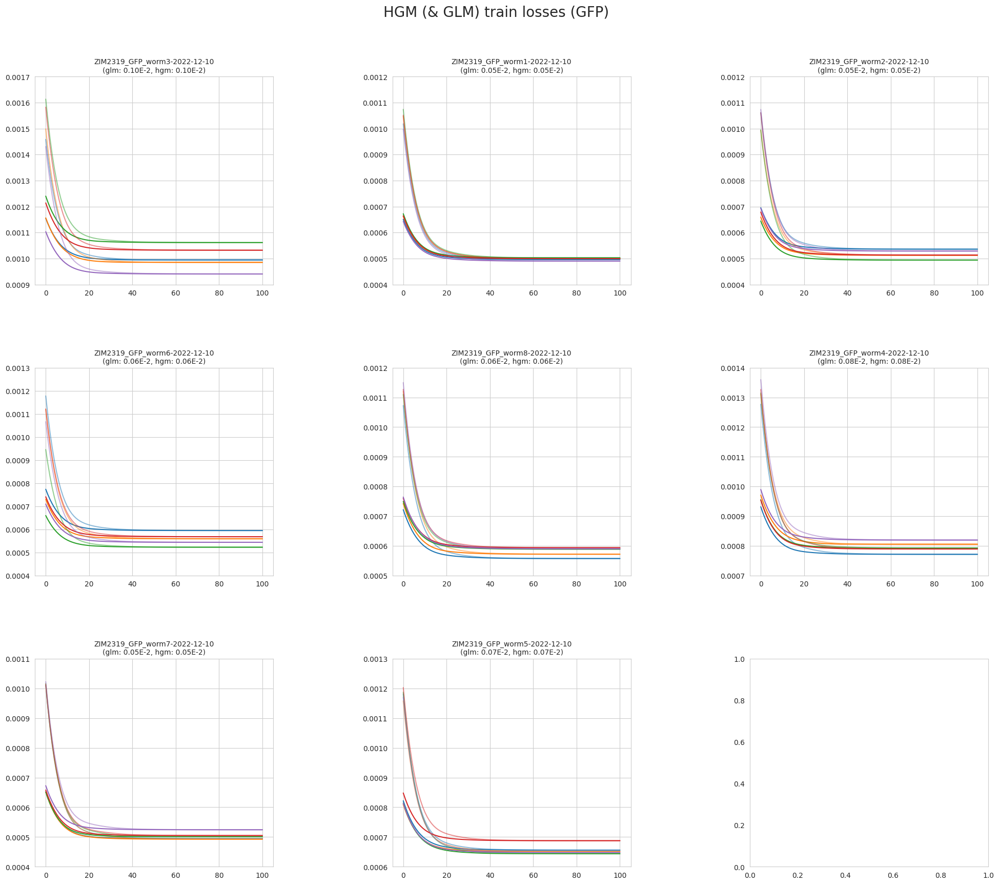

In [55]:
n_plots = 9
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(24, 20))
for i in range(n_plots):
	#axes[i // dim, i % dim].set_xticklabels([])
	#axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

for i, (losses_per_split_glm, losses_per_split_hgm) in enumerate(zip(gfp_models_t_losses_glm[:9], gfp_models_t_losses_hgm[:9])):
	colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
	for j, (losses_glm, losses_hgm) in enumerate(zip(losses_per_split_glm, losses_per_split_hgm)):
		axes[i // dim, i % dim].plot(losses_glm, color=colors[j], alpha=0.5)
		axes[i // dim, i % dim].plot(losses_hgm, color=colors[j])
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{gfp_filenames[i][:-14]}\n(glm: {np.average(losses_per_split_glm[:, -1], axis=0)*100:.2f}E-2, hgm: {np.average(losses_per_split_hgm[:, -1], axis=0)*100:.2f}E-2)', fontsize=10)

	yticks = axes[i // dim, i % dim].get_yticks()
	axes[i // dim, i % dim].set_yticks(yticks)
	#axes[i // dim, i % dim].set_yticklabels([f'{tick * 100:.2f}E-2' for tick in yticks])

fig.subplots_adjust(hspace=0.4, wspace=0.5)
fig.suptitle('HGM (& GLM) train losses (GFP)', fontsize=20, y=0.95)
plt.savefig('./out/sep-pca-hgm-glm-train-mse-gfp')
pass

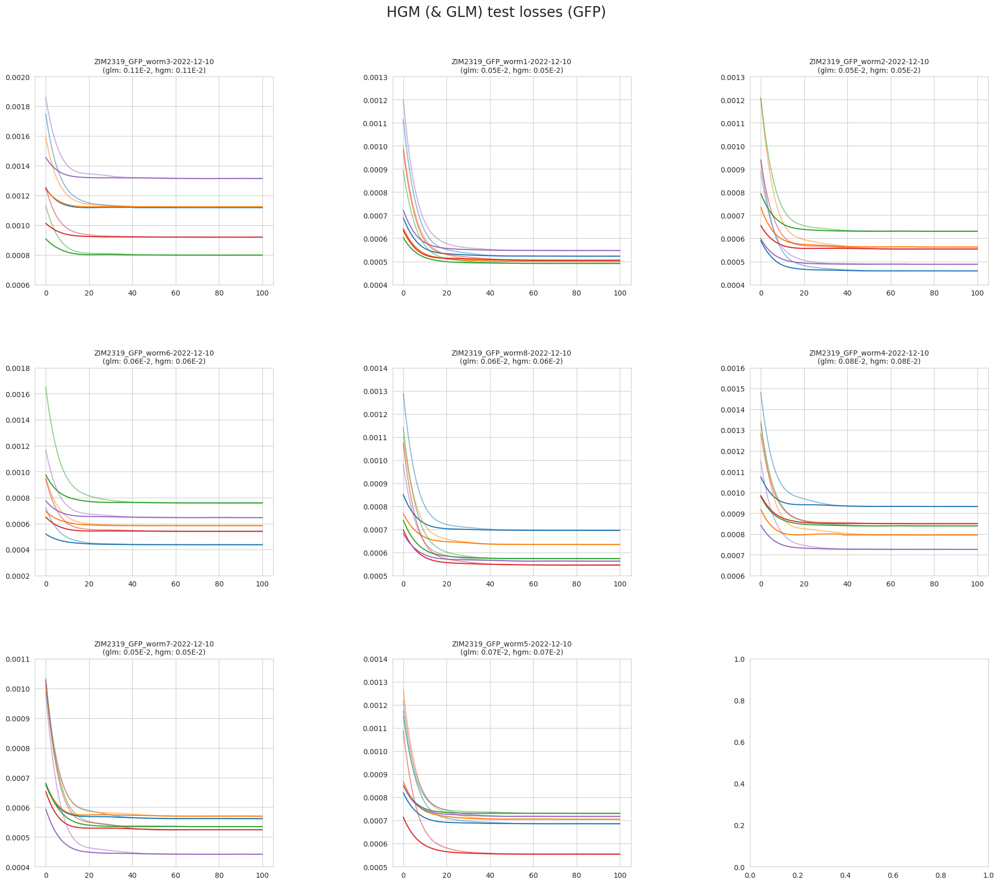

In [56]:
n_plots = 9
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(24, 20))
for i in range(n_plots):
	#axes[i // dim, i % dim].set_xticklabels([])
	#axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

for i, (losses_per_split_glm, losses_per_split_hgm) in enumerate(zip(gfp_models_losses_glm[:9], gfp_models_losses_hgm[:9])):
	colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
	for j, (losses_glm, losses_hgm) in enumerate(zip(losses_per_split_glm, losses_per_split_hgm)):
		axes[i // dim, i % dim].plot(losses_glm, color=colors[j], alpha=0.5)
		axes[i // dim, i % dim].plot(losses_hgm, color=colors[j])
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{gfp_filenames[i][:-14]}\n(glm: {np.average(losses_per_split_glm[:, -1], axis=0)*100:.2f}E-2, hgm: {np.average(losses_per_split_hgm[:, -1], axis=0)*100:.2f}E-2)', fontsize=10)

	yticks = axes[i // dim, i % dim].get_yticks()
	axes[i // dim, i % dim].set_yticks(yticks)
	#axes[i // dim, i % dim].set_yticklabels([f'{tick * 100:.2f}E-2' for tick in yticks])

fig.subplots_adjust(hspace=0.4, wspace=0.5)
fig.suptitle('HGM (& GLM) test losses (GFP)', fontsize=20, y=0.95)
plt.savefig('./out/sep-pca-hgm-glm-test-mse-gfp')
pass

# assemble

In [57]:
neurons_labels = [traces_residual[i].columns for i in range(len(filenames))]

unique_labels = sorted(list(set([l for label in neurons_labels for l in label])))
unique_labels_filtered = [label for label in unique_labels if label != '' and label[-1] != '_']

neuron_scores = dict()
for label_list, score_glm_list, score_hgm_list in zip(neurons_labels, models_scores_glm, models_scores_hgm):
	for i in range(len(label_list)):
		label = label_list[i]
		if label != '' and label[-1] != '_':
			score_glm_new, score_hgm_new = np.array(score_glm_list[i]), np.array(score_hgm_list[i])
			if len(score_hgm_new.shape) == 0:
				score_glm_new = score_glm_new.reshape(1, 1)
				score_hgm_new = score_hgm_new.reshape(1, 1)
			if label not in neuron_scores.keys():
				neuron_scores[label] = (score_glm_new, score_hgm_new)
			else:
				score_glm_prev, score_hgm_prev = neuron_scores[label]
				neuron_scores[label] = (np.vstack([score_glm_prev, score_glm_new]), np.vstack([score_hgm_prev, score_hgm_new]))

In [58]:
gfp_neurons_labels = [gfp_traces_residual[i].columns for i in range(len(gfp_filenames))]

gfp_unique_labels = sorted(list(set([l for label in gfp_neurons_labels for l in label])))
gfp_unique_labels_filtered = [label for label in gfp_unique_labels if label != '' and label[-1] != '_']

gfp_neuron_scores = dict()
for label_list, score_glm_list, score_hgm_list in zip(gfp_neurons_labels, gfp_models_scores_glm, gfp_models_scores_hgm):
	for i in range(len(label_list)):
		label = label_list[i]
		if label != '' and label[-1] != '_':
			score_glm_new, score_hgm_new = np.array(score_glm_list[i]), np.array(score_hgm_list[i])
			if len(score_hgm_new.shape) == 0:
				score_glm_new = score_glm_new.reshape(1, 1)
				score_hgm_new = score_hgm_new.reshape(1, 1)
			if label not in gfp_neuron_scores.keys():
				gfp_neuron_scores[label] = (score_glm_new, score_hgm_new)
			else:
				score_glm_prev, score_hgm_prev = gfp_neuron_scores[label]
				gfp_neuron_scores[label] = (np.vstack([score_glm_prev, score_glm_new]), np.vstack([score_hgm_prev, score_hgm_new]))

# Plot

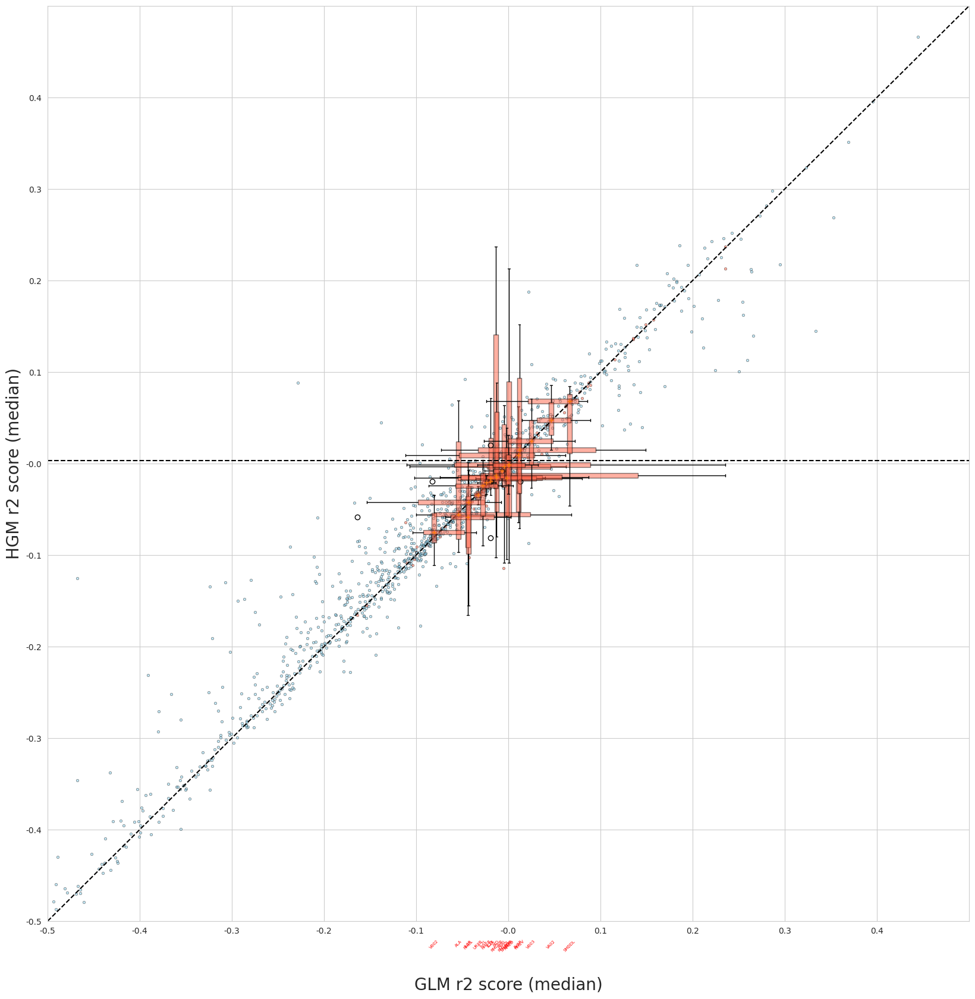

In [59]:
threshold = 0.95

plt.figure(figsize=(20, 20))
plt.xlabel('GLM r2 score (median)', fontsize=20, labelpad=50)
plt.ylabel('HGM r2 score (median)', fontsize=20)

max_x = 0.5
max_y = 0.5
plt.xlim(-max_x, max_x)
plt.ylim(-max_y, max_y)

plt.plot([-max_x, max_x + 1], [-max_y, max_y + 1], color='black', linestyle='--')


# GFP =============================================================================================================
gfp_boxplot_xticks, gfp_boxplot_xtick_labels = list(), list()

keys = gfp_neuron_scores.keys()
for key in keys:
	scores_glm, scores_hgm = gfp_neuron_scores[key]
	if len(scores_hgm.shape) == 0:
		scores_glm = scores_glm.reshape(1, 1)
		scores_hgm = scores_hgm.reshape(1, 1)

	plt.scatter(scores_glm, scores_hgm, s=10, c='tomato', edgecolor='black', linewidth=0.5, alpha=0.5)

	x = np.median(scores_glm)
	y = np.median(scores_hgm)

	gfp_boxplot_xticks.append(x)
	gfp_boxplot_xtick_labels.append(f'{key}')

	boxplot_h = plt.boxplot(scores_hgm, positions=[x], widths=0.005 * max_x / max_y, patch_artist=True, showfliers=True)
	boxplot_v = plt.boxplot(scores_glm, positions=[y], widths=0.005 * max_y / max_x, patch_artist=True, showfliers=True, vert=False)
	for box in [boxplot_h, boxplot_v]:
		for patch in box['boxes']:
			patch.set_facecolor('tomato')
			patch.set_alpha(0.5)

for x, label in zip(gfp_boxplot_xticks, gfp_boxplot_xtick_labels):
	plt.text(x, -max_y-0.02, label, color='red', ha='center', va='top', rotation=45, fontsize=5, transform=plt.gca().transData)
# =================================================================================================================


gfp_high_score_hgm_impr = np.quantile(np.concatenate([pair[1] - pair[0] for pair in gfp_neuron_scores.values()]), threshold)
gfp_high_score_glm = np.quantile(np.concatenate([pair[0] for pair in gfp_neuron_scores.values()]), threshold)
gfp_high_score_hgm = np.quantile(np.concatenate([pair[1] for pair in gfp_neuron_scores.values()]), threshold)
plt.plot([-max_x, max_x + 1], [gfp_high_score_hgm_impr, gfp_high_score_hgm_impr], color='black', linestyle='--')


# GCAMP ===========================================================================================================
boxplot_xticks, boxplot_xtick_labels = list(), list()

keys = neuron_scores.keys()
for key in keys:
	scores_glm, scores_hgm = neuron_scores[key]
	if len(scores_hgm.shape) == 0:
		scores_glm = scores_glm.reshape(1, 1)
		scores_hgm = scores_hgm.reshape(1, 1)

	plt.scatter(scores_glm, scores_hgm, s=10, c='skyblue', edgecolor='black', linewidth=0.5, alpha=0.5)

	x = np.median(scores_glm)
	# if x < gfp_high_score_glm: continue
	y = np.median(scores_hgm)
	if y < gfp_high_score_hgm: continue

	boxplot_xticks.append(x)
	boxplot_xtick_labels.append(f'{key}')

	boxplot_h = plt.boxplot(scores_hgm, positions=[x], widths=0.005 * max_x / max_y, patch_artist=True, showfliers=True)
	boxplot_v = plt.boxplot(scores_glm, positions=[y], widths=0.005 * max_y / max_x, patch_artist=True, showfliers=True, vert=False)
	for box in [boxplot_h, boxplot_v]:
		for patch in box['boxes']:
			patch.set_facecolor('skyblue')
			patch.set_alpha(0.5)

for x, label in zip(boxplot_xticks, boxplot_xtick_labels):
	plt.text(x, -max_y-0.02, label, color='blue', ha='center', va='top', rotation=45, fontsize=5, transform=plt.gca().transData)
# =================================================================================================================


plt.xticks(np.arange(-max_x, max_x, 0.1), [f'{val:.1f}' for val in np.arange(-max_x, max_x, 0.1)])
plt.yticks(np.arange(-max_y, max_y, 0.1), [f'{val:.1f}' for val in np.arange(-max_y, max_y, 0.1)])

plt.savefig('out/sep-pca-hgm-vs-glm-scores', dpi=300)

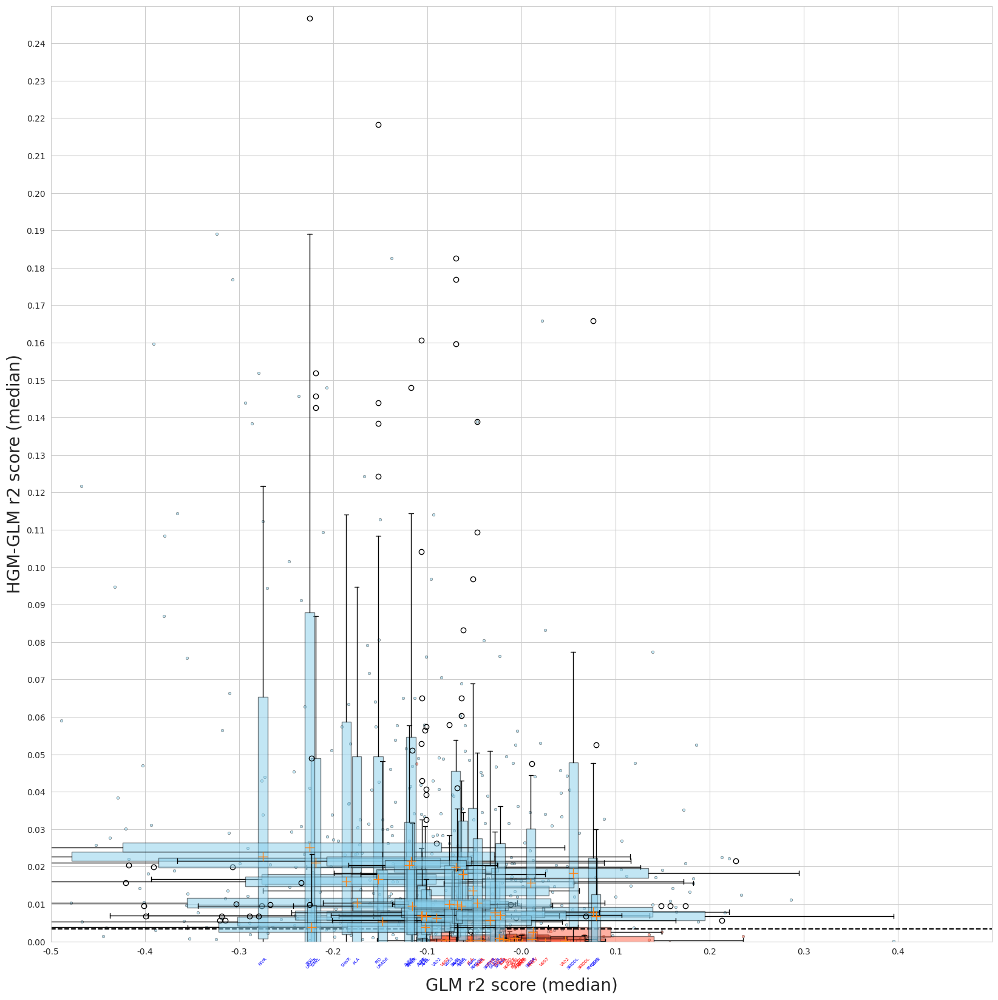

In [60]:
threshold = 0.95

plt.figure(figsize=(20, 20))
plt.xlabel('GLM r2 score (median)', fontsize=20, labelpad=25)
plt.ylabel('HGM-GLM r2 score (median)', fontsize=20)

max_x = 0.5
max_y = 0.25
plt.xlim(-max_x, max_x)
plt.ylim(0, max_y)

# plt.plot([-max_x, max_x + 1], [0, max_y + 1], color='black', linestyle='--')


# GFP =============================================================================================================
gfp_boxplot_xticks, gfp_boxplot_xtick_labels = list(), list()

keys = gfp_neuron_scores.keys()
for key in keys:
	scores_glm, scores_hgm = gfp_neuron_scores[key]
	if len(scores_hgm.shape) == 0:
		scores_glm = scores_glm.reshape(1, 1)
		scores_hgm = scores_hgm.reshape(1, 1)

	x = np.median(scores_glm)
	y = np.median(scores_hgm - scores_glm)

	plt.scatter(scores_glm, scores_hgm - scores_glm, s=10, c='tomato', edgecolor='black', linewidth=0.5, alpha=0.5)

	gfp_boxplot_xticks.append(x)
	gfp_boxplot_xtick_labels.append(f'{key}')

	boxplot_v = plt.boxplot(scores_hgm - scores_glm, positions=[x], widths=0.005 * max_x / max_y, patch_artist=True, showfliers=True)
	boxplot_h = plt.boxplot(scores_glm, positions=[y], widths=0.005 * max_y / max_x, patch_artist=True, showfliers=True, vert=False)
	for box in [boxplot_v, boxplot_h]:
		for patch in box['boxes']:
			patch.set_facecolor('tomato')
			patch.set_alpha(0.5)

for x, label in zip(gfp_boxplot_xticks, gfp_boxplot_xtick_labels):
	# if x >= 0:
	plt.text(x, -0.004, label, color='red', ha='center', va='top', rotation=45, fontsize=5, transform=plt.gca().transData)
# =================================================================================================================


# gfp_high_score_glm = np.quantile(np.concatenate([pair[0] for pair in gfp_neuron_scores.values()]), threshold)
gfp_high_score_hgm_impr = np.quantile(np.concatenate([pair[1] - pair[0] for pair in gfp_neuron_scores.values()]), threshold)
plt.plot([-max_x, max_x + 1], [gfp_high_score_hgm_impr, gfp_high_score_hgm_impr], color='black', linestyle='--')


# GCAMP ===========================================================================================================
boxplot_xticks, boxplot_xtick_labels = list(), list()

keys = neuron_scores.keys()
for key in keys:
	scores_glm, scores_hgm = neuron_scores[key]
	if len(scores_hgm.shape) == 0:
		scores_glm = scores_glm.reshape(1, 1)
		scores_hgm = scores_hgm.reshape(1, 1)

	x = np.median(scores_glm)
	# if x < gfp_high_score_glm: continue
	y = np.median(scores_hgm - scores_glm)
	if y < gfp_high_score_hgm_impr: continue

	plt.scatter(scores_glm, scores_hgm - scores_glm, s=10, c='skyblue', edgecolor='black', linewidth=0.5, alpha=0.5)

	boxplot_xticks.append(x)
	boxplot_xtick_labels.append(f'{key}')

	boxplot_v = plt.boxplot(scores_hgm - scores_glm, positions=[x], widths=0.005 * max_x / max_y, patch_artist=True, showfliers=True)
	boxplot_h = plt.boxplot(scores_glm, positions=[y], widths=0.005 * max_y / max_x, patch_artist=True, showfliers=True, vert=False)
	for box in [boxplot_v, boxplot_h]:
		for patch in box['boxes']:
			patch.set_facecolor('skyblue')
			patch.set_alpha(0.5)

for x, label in zip(boxplot_xticks, boxplot_xtick_labels):
	# if x >= 0:
	plt.text(x, -0.004, label, color='blue', ha='center', va='top', rotation=45, fontsize=5, transform=plt.gca().transData)
# =================================================================================================================


plt.xticks(np.arange(-max_x, max_x, 0.1), [f'{val:.1f}' for val in np.arange(-max_x, max_x, 0.1)])
plt.yticks(np.arange(0, max_y, 0.01), [f'{val:.2f}' for val in np.arange(0, max_y, 0.01)])

plt.savefig('out/sep-pca-hgm-vs-glm-scores-rel', dpi=300)

# Final models

In [61]:
# todo

## some traces

In [62]:
residuals_pred_glm_df = pd.DataFrame(residuals_pred_glm, columns=neuronal_traces.columns)
heatmap = discrete_states['FWD'].values.reshape(-1, 1) * 0.1

dim1, dim2 = 20, 2
fig, axes = plt.subplots(dim1, dim2, figsize=(20, 45), constrained_layout=True)
for i in range(dim1 * dim2):
	#axes[i // dim2, i % dim2].set_xticklabels([])
	#axes[i // dim2, i % dim2].set_yticklabels([])
	axes[i // dim2, i % dim2].grid(False)

i = 0
for key in residuals_pred_glm_df:
	if key != '':
		min_val, max_val = min(residuals_pred_glm_df[key]), max(residuals_pred_glm_df[key])
		axes[i // dim2, i % dim2].imshow(
			heatmap.T, aspect='auto', cmap='rainbow', interpolation='nearest', alpha=0.3, extent=[0, heatmap.shape[0], min_val, max_val]
		)
		axes[i // dim2, i % dim2].plot(residuals_pred_glm_df[key], color='black', linewidth=1.0)
		axes[i // dim2, i % dim2].grid(False)
		axes[i // dim2, i % dim2].set_title(f'{key}', fontsize=12)
		i += 1

fig.text(0.5, 1.03, 'Predicted Signals (GLM)', ha='center', fontsize=20)
fig.legend(
    handles=[patches.Patch(color=plt.get_cmap('rainbow')(0.0), alpha=0.3, label='reversal')],
    loc='upper center',
    bbox_to_anchor=(0.5, 1.02),
    ncol=1,
    fontsize='large'
)

NameError: name 'residuals_pred_glm' is not defined

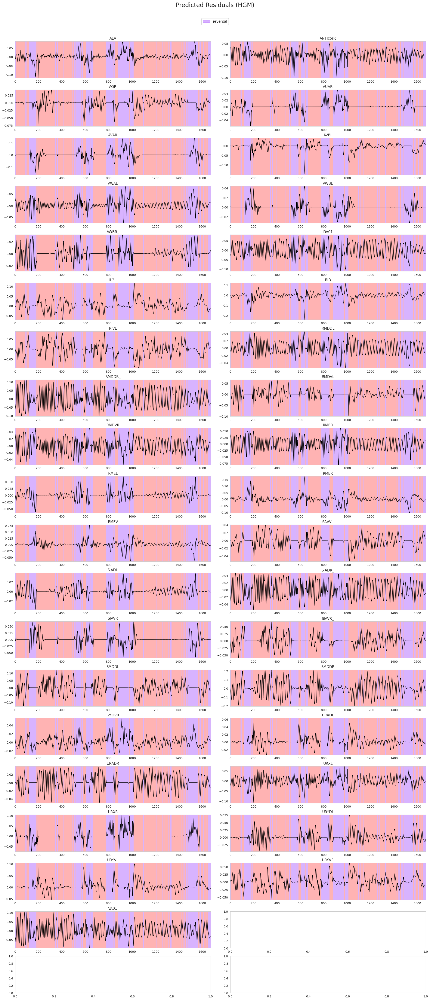

In [16]:
residuals_pred_hgm_df = pd.DataFrame(residuals_pred_hgm, columns=neuronal_traces.columns)
heatmap = discrete_states['FWD'].values.reshape(-1, 1) * 0.1

dim1, dim2 = 20, 2
fig, axes = plt.subplots(dim1, dim2, figsize=(20, 45), constrained_layout=True)
for i in range(dim1 * dim2):
	#axes[i // dim2, i % dim2].set_xticklabels([])
	#axes[i // dim2, i % dim2].set_yticklabels([])
	axes[i // dim2, i % dim2].grid(False)

i = 0
for key in residuals_pred_hgm_df:
	if key != '':
		min_val, max_val = min(residuals_pred_hgm_df[key]), max(residuals_pred_hgm_df[key])
		axes[i // dim2, i % dim2].imshow(
			heatmap.T, aspect='auto', cmap='rainbow', interpolation='nearest', alpha=0.3, extent=[0, heatmap.shape[0], min_val, max_val]
		)
		axes[i // dim2, i % dim2].plot(residuals_pred_hgm_df[key], color='black', linewidth=1.0)
		axes[i // dim2, i % dim2].grid(False)
		axes[i // dim2, i % dim2].set_title(f'{key}', fontsize=12)
		i += 1

fig.text(0.5, 1.03, 'Predicted Residuals (HGM)', ha='center', fontsize=20)
fig.legend(
    handles=[patches.Patch(color=plt.get_cmap('rainbow')(0.0), alpha=0.3, label='reversal')],
    loc='upper center',
    bbox_to_anchor=(0.5, 1.02),
    ncol=1,
    fontsize='large'
)

plt.savefig('out/traces_single_residuals_predicted.png', dpi=300)

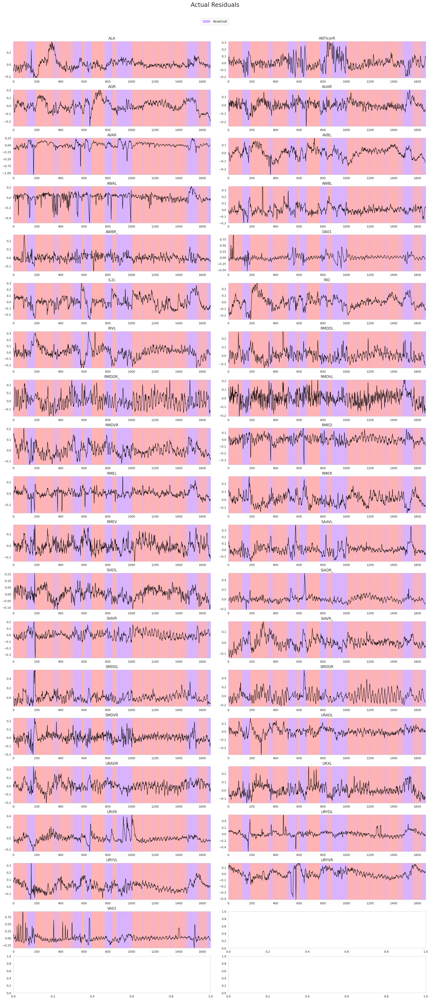

In [17]:
signal_residual_df = pd.DataFrame(data=signal_residual, columns=neuronal_traces.columns)

dim1, dim2 = 20, 2
fig, axes = plt.subplots(dim1, dim2, figsize=(20, 45), constrained_layout=True)
for i in range(dim1 * dim2):
	#axes[i // dim2, i % dim2].set_xticklabels([])
	#axes[i // dim2, i % dim2].set_yticklabels([])
	axes[i // dim2, i % dim2].grid(False)

i = 0
for key in signal_residual_df:
	if key != '':
		min_val, max_val = min(signal_residual_df[key]), max(signal_residual_df[key])
		axes[i // dim2, i % dim2].imshow(
			heatmap.T, aspect='auto', cmap='rainbow', interpolation='nearest', alpha=0.3, extent=[0, heatmap.shape[0], min_val, max_val]
		)
		axes[i // dim2, i % dim2].plot(signal_residual_df[key], color='black', linewidth=1.0)
		axes[i // dim2, i % dim2].grid(False)
		axes[i // dim2, i % dim2].set_title(f'{key}', fontsize=12)
		i += 1

fig.text(0.5, 1.03, 'Actual Residuals', ha='center', fontsize=20)
fig.legend(
    handles=[patches.Patch(color=plt.get_cmap('rainbow')(0.0), alpha=0.3, label='reversal')],
    loc='upper center',
    bbox_to_anchor=(0.5, 1.02),
    ncol=1,
    fontsize='large'
)

plt.savefig('out/traces_single_residuals.png', dpi=300)

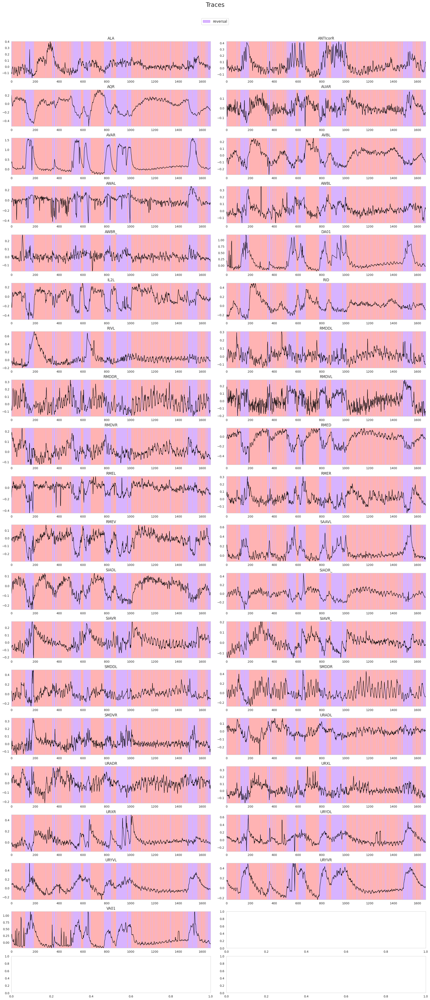

In [18]:
dim1, dim2 = 20, 2
fig, axes = plt.subplots(dim1, dim2, figsize=(20, 45), constrained_layout=True)
for i in range(dim1 * dim2):
	#axes[i // dim2, i % dim2].set_xticklabels([])
	#axes[i // dim2, i % dim2].set_yticklabels([])
	axes[i // dim2, i % dim2].grid(False)

i = 0
for key in neuronal_traces:
	if key != '':
		min_val, max_val = min(neuronal_traces[key]), max(neuronal_traces[key])
		axes[i // dim2, i % dim2].imshow(
			heatmap.T, aspect='auto', cmap='rainbow', interpolation='nearest', alpha=0.3, extent=[0, heatmap.shape[0], min_val, max_val]
		)
		axes[i // dim2, i % dim2].plot(neuronal_traces[key], color='black', linewidth=1.0)
		axes[i // dim2, i % dim2].grid(False)
		axes[i // dim2, i % dim2].set_title(f'{key}', fontsize=12)
		i += 1

fig.text(0.5, 1.03, 'Traces', ha='center', fontsize=20)
fig.legend(
    handles=[patches.Patch(color=plt.get_cmap('rainbow')(0.0), alpha=0.3, label='reversal')],
    loc='upper center',
    bbox_to_anchor=(0.5, 1.02),
    ncol=1,
    fontsize='large'
)

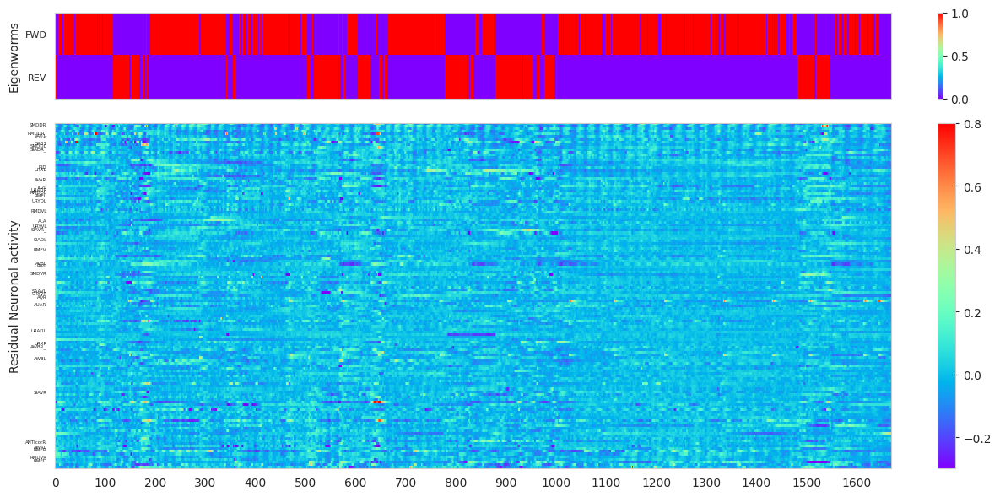

In [7]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

ews = eigenworms.values
ds = discrete_states[selection].values
signal = neuronal_traces.values




cca_residual = CCA(n_components=5, scale=False)  # cca = CCA(n_components=5)
signal_residual_reduced, ews_reduced = cca_residual.fit_transform(signal_residual, ews)
signal_residual_reconstructed, ews_reconstructed = cca_residual.inverse_transform(signal_residual_reduced, ews_reduced)

signal_residual_indices = np.argsort(cca_residual.x_loadings_[:, 0])






fig, (ax_top, ax_3tom) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [1, 4]})

im_top = ax_top.imshow(ds.T, aspect='auto', cmap='rainbow', interpolation='nearest')
ax_top.set_ylabel("ds")
ax_top.set_yticks(np.arange(len(ds.T)))
ax_top.set_yticklabels(discrete_states[selection].columns, fontsize=8)
ax_top.set_xticks(np.arange(0, len(ds), 100))
fig.colorbar(im_top, ax=ax_top, orientation='vertical', fraction=0.05)
ax_top.grid(False)

im_bottom = ax_3tom.imshow(np.clip(signal_residual.T[signal_residual_indices], -0.3, 0.8), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_3tom.set_ylabel("Residual Neuronal activity")
ax_3tom.set_yticks(np.arange(len(signal_residual.T)))
ax_3tom.set_yticklabels(neuronal_traces.columns[signal_residual_indices], fontsize=4)
ax_3tom.set_xticks(np.arange(0, len(signal_residual), 100))
fig.colorbar(im_bottom, ax=ax_3tom, orientation='vertical', fraction=0.05)
ax_3tom.grid(False)

plt.tight_layout()
plt.show()

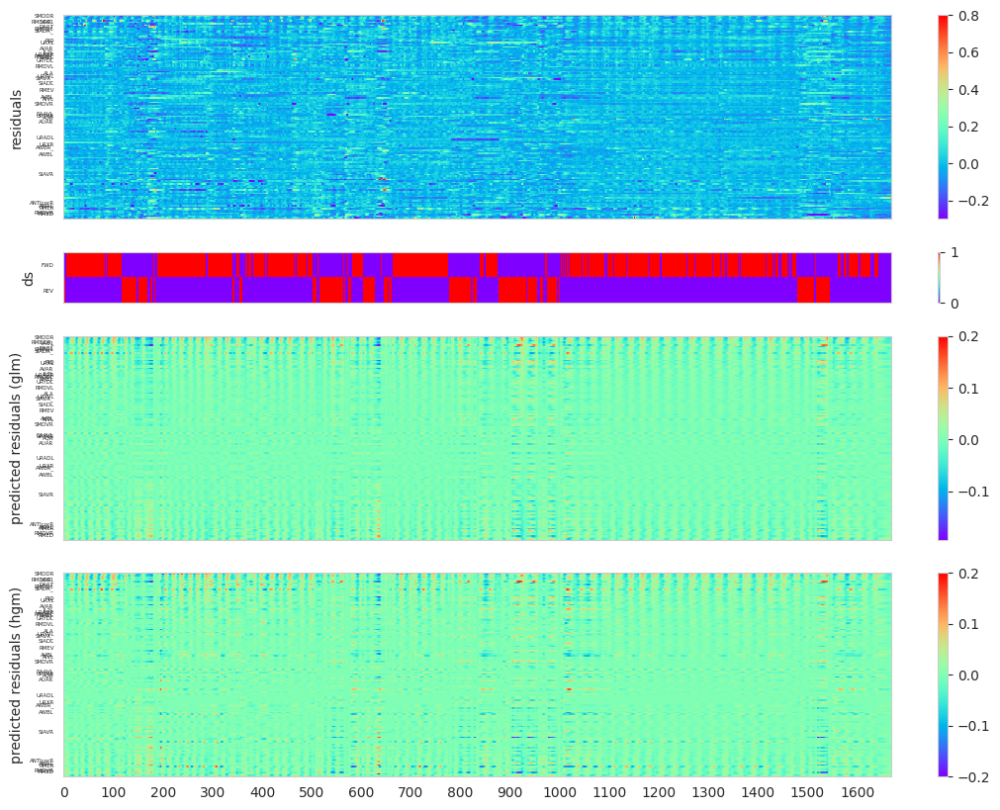

In [12]:


fig, (ax_1, ax_2, ax_3, ax_4) = plt.subplots(4, 1, figsize=(12, 10), sharex=True, gridspec_kw={'height_ratios': [4, 1, 4, 4]})

im_1 = ax_1.imshow(np.clip(signal_residual.T[signal_residual_indices], -0.3, 0.8), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_1.set_ylabel("residuals")
ax_1.set_yticks(np.arange(len(signal_residual.T)))
ax_1.set_yticklabels(neuronal_traces.columns[signal_residual_indices], fontsize=4)
ax_1.set_xticks(np.arange(0, len(signal_residual), 100))
fig.colorbar(im_1, ax=ax_1, orientation='vertical', fraction=0.05)
ax_1.grid(False)

im_2 = ax_2.imshow(ds.T, aspect='auto', cmap='rainbow', interpolation='nearest')
ax_2.set_ylabel("ds")
ax_2.set_yticks(np.arange(len(ds.T)))
ax_2.set_yticklabels(discrete_states[selection].columns, fontsize=4)
ax_2.set_xticks(np.arange(0, len(ds), 100))
fig.colorbar(im_2, ax=ax_2, orientation='vertical', fraction=0.05)
ax_2.grid(False)

im_3 = ax_3.imshow(np.clip(residuals_pred_glm.T[signal_residual_indices], -0.2, 0.2), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_3.set_ylabel("predicted residuals (glm)")
ax_3.set_yticks(np.arange(len(residuals_pred_glm.T)))
ax_3.set_yticklabels(neuronal_traces.columns[signal_residual_indices], fontsize=4)
ax_3.set_xticks(np.arange(0, len(residuals_pred_glm), 100))
fig.colorbar(im_3, ax=ax_3, orientation='vertical', fraction=0.05)
ax_3.grid(False)

im_4 = ax_4.imshow(np.clip(residuals_pred_hgm.T[signal_residual_indices], -0.2, 0.2), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_4.set_ylabel("predicted residuals (hgm)")
ax_4.set_yticks(np.arange(len(residuals_pred_hgm.T)))
ax_4.set_yticklabels(neuronal_traces.columns[signal_residual_indices], fontsize=4)
ax_4.set_xticks(np.arange(0, len(residuals_pred_hgm), 100))
fig.colorbar(im_4, ax=ax_4, orientation='vertical', fraction=0.05)
ax_4.grid(False)

plt.savefig('out/traces_residuals_predicted.png', dpi=300)